# Tutorial Class 04 Set 01

## Prepare these Exercises before Class

### Exercise 3

In [3]:
library(tidyverse)

In [4]:
asx_data <- read_csv("data/asx_200_2024.csv")

Rows: 200 Columns: 30
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (10): gvkey, curcd, datadate, conm, fic, conml, sector, indgroup, indust...
dbl (20): fyear, fyr, at, capx, shareequity, dlc, dltt, dvp, ebit, netprofit...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [5]:
firm_strategy <-
  asx_data |>
  filter(sale > 0, at > 0) |>
  mutate(
    profit_margin = ebit / sale,
    asset_turnover = sale / at
  )

### Exercise 4

In [6]:
firm_strategy_check <-
  firm_strategy |>
  select(conml, ebit, at, sale, profit_margin, asset_turnover)

In [7]:
firm_strategy_check |>
  slice_head(n = 10)

conml,ebit,at,sale,profit_margin,asset_turnover
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
BHP Group Ltd,22771.0,102362,55658.0,0.40912358,0.5437369
Telstra Group Limited,3712.0,45550,22928.0,0.16189812,0.5033589
CSL Ltd,3896.0,38022,14690.0,0.26521443,0.3863553
Transurban Group,1132.0,36694,4119.0,0.27482399,0.1122527
Woolworths Group Ltd,3100.0,33936,67922.0,0.04564059,2.0014734
Fortescue Ltd,8520.0,30060,18220.0,0.46761800,0.6061211
Wesfarmers Ltd,3849.0,27309,44189.0,0.08710313,1.6181112
Ramsay Health Care Ltd,938.7,20894,16660.2,0.05634386,0.7973677
Qantas Airways Ltd,2198.0,20564,20114.0,0.10927712,0.9781171


## In-Class Exercises

### Exercise 5

In [8]:
firm_strategy |>
  slice_max(profit_margin, n = 5) |>
  select(conml, industry, profit_margin, asset_turnover)

conml,industry,profit_margin,asset_turnover
<chr>,<chr>,<dbl>,<dbl>
Aft Corporation Ltd,Building Products,0.9453009,0.0520372
APA Group,Gas Utilities,0.6087529,0.1553443
Fortescue Ltd,Metals & Mining,0.4676180,0.6061211
Perseus Mining Ltd,Metals & Mining,0.4506058,0.5165708
Emerald Resources NL,Metals & Mining,0.4280829,0.5208612


In [9]:
firm_strategy |>
  slice_max(asset_turnover, n = 5) |>
  select(conml, industry, profit_margin, asset_turnover)

conml,industry,profit_margin,asset_turnover
<chr>,<chr>,<dbl>,<dbl>
Peoplein Limited,Professional Services,0.010606953,3.018577
Jb Hi-Fi Ltd,Specialty Retail,0.067282432,2.751219
Mader Group Ltd,Commercial Services & Supplies,0.092984640,2.291710
Monadelphous Group Ltd Mndda,Construction & Engineering,0.041513159,2.271804
Graincorp Ltd,Consumer Staples Distribution & Retail (New Name),0.003334973,2.239939


### Exercise 6

In [10]:
industry_summary <-
  firm_strategy |>
  group_by(industry) |>
  summarise(
    n_firms = n(),
    avg_profit_margin = mean(profit_margin, na.rm = TRUE),
    avg_asset_turnover = mean(asset_turnover, na.rm = TRUE)
  )

In [11]:
industry_summary |>
  filter(n_firms >= 3) |>
  arrange(desc(avg_profit_margin))

industry,n_firms,avg_profit_margin,avg_asset_turnover
<chr>,<int>,<dbl>,<dbl>
Building Products,3,0.42285722,0.4198521
Interactive Media & Services,4,0.32817801,0.3396100
Insurance,3,0.24656033,0.2760308
Software,4,0.21179838,0.5539411
Financial Services (New Name),4,0.19506814,0.3556962
Automobile Components (New Name),3,0.18275401,0.6557444
Diversified Consumer Services,3,0.16544826,0.4969783
Commercial Services & Supplies,7,0.14685573,0.9939687
Professional Services,4,0.14445095,1.1754022


In [12]:
industry_summary |>
  filter(n_firms >= 3) |>
  arrange(desc(avg_asset_turnover))

industry,n_firms,avg_profit_margin,avg_asset_turnover
<chr>,<int>,<dbl>,<dbl>
Consumer Staples Distribution & Retail (New Name),4,0.04494600,1.8697141
Construction & Engineering,11,0.07649510,1.4716446
Specialty Retail,14,0.10340479,1.2912573
Broadline Retail (New Name),4,0.10124671,1.1839357
Professional Services,4,0.14445095,1.1754022
Food Products,7,0.06290191,1.1476535
Trading Companies & Distributors,5,0.09476225,1.0880643
Commercial Services & Supplies,7,0.14685573,0.9939687
Media,4,0.07830369,0.9494900


### Exercise 8

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”


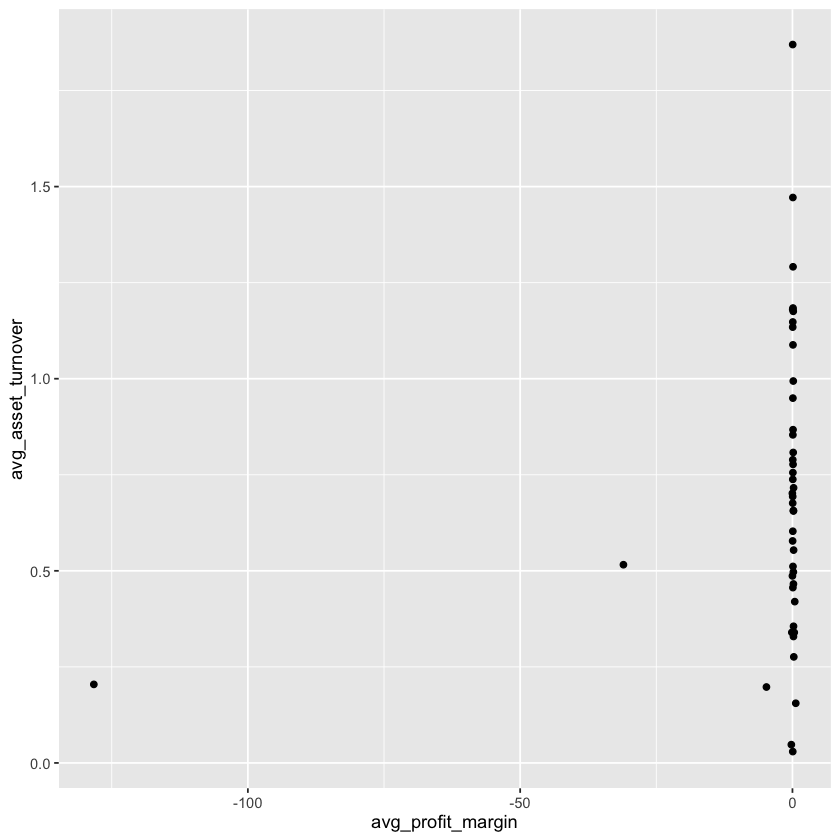

In [13]:
industry_summary |>
  ggplot(aes(x = avg_profit_margin, y = avg_asset_turnover)) +
  geom_point()

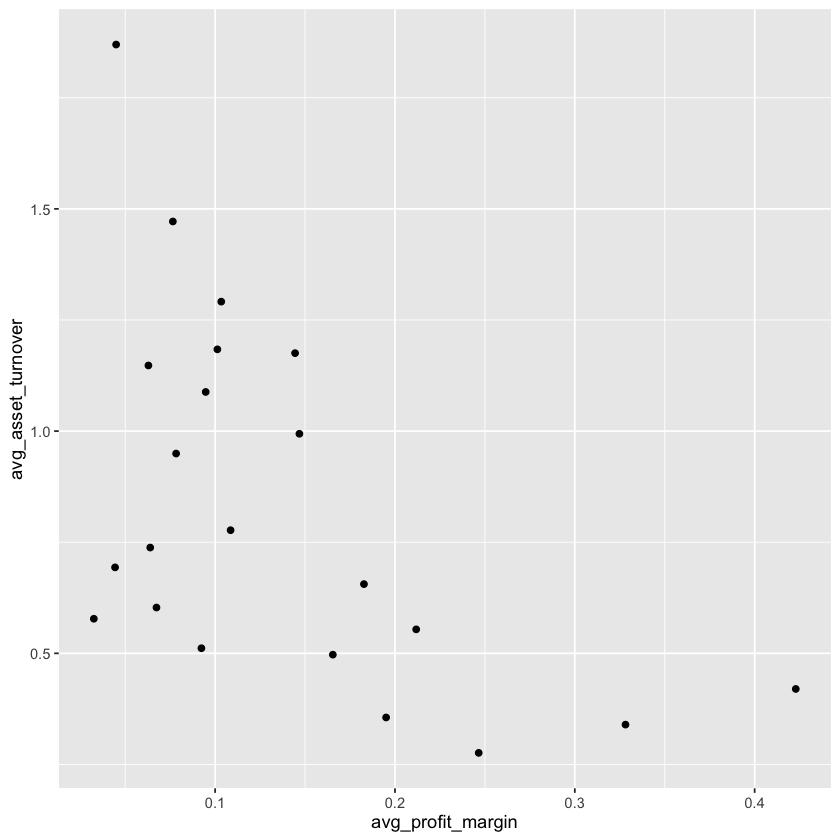

In [14]:
industry_summary |>
  filter(
    n_firms >= 3, 
    avg_profit_margin > -0.5
  ) |>
  ggplot(aes(x = avg_profit_margin, y = avg_asset_turnover)) +
  geom_point()

`geom_smooth()` using formula = 'y ~ x'


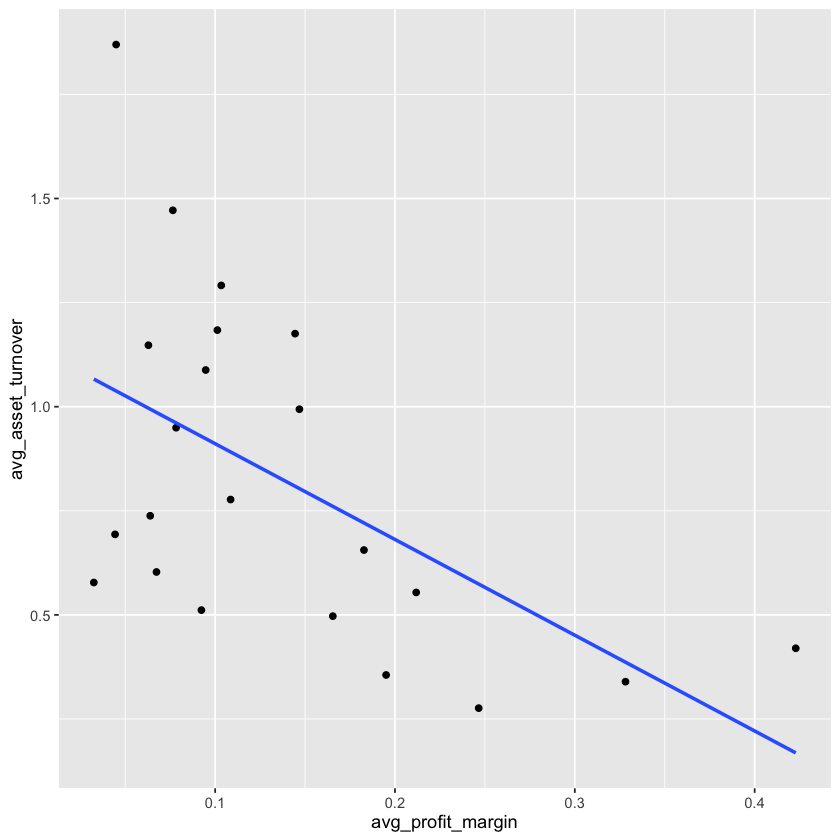

In [15]:
industry_summary |>
  filter(n_firms >= 3, avg_profit_margin > -0.5) |>
  ggplot(aes(x = avg_profit_margin, y = avg_asset_turnover)) +
  geom_point() +
  geom_smooth(method = "lm", se = FALSE)